# EDA Overview:


Data Overview:

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 100)

PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / 'data' / 'raw' / 'listings.csv'

df = pd.read_csv(DATA_PATH)
df = df.dropna(subset=['price'])

all_missing = df.columns[df.isna().all()].tolist()
df_eda = df.drop(columns=all_missing).copy()

df_eda['price'] = pd.to_numeric(df_eda["price"].astype(str).str.replace(r"[$,]", "", regex=True), errors="coerce")
df_eda['price'] = df_eda['price'].astype(float)

display(f"Dataset shape: {df_eda.shape[0]} rows × {df_eda.shape[1]} columns")
display(df_eda.head())

In [ ]:
df_eda.info()

In [ ]:
display(df.describe().T)

Data Quality:

In [ ]:
missing_summary = pd.DataFrame({
    "missing_count": df_eda.isna().sum(),
    "missing_percentage": df_eda.isna().mean() * 100,
    "dtype": df_eda.dtypes.astype(str)
})

missing_summary = (
    missing_summary[missing_summary["missing_count"] > 0]
    .sort_values("missing_percentage", ascending=False)
)

display(missing_summary)

print("Duplicate rows:", df.duplicated().sum())

Target Variable Analysis (Price)

In [ ]:
display(
    df_eda[[
        "price",
        "price_quote_price_per_night",
        "price_quote_total_price",
        "price_quote_checkin_date",
        "price_quote_checkout_date"
    ]].head(20)
)

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df_eda, x="price", bins=1000, log_scale=True)

plt.title("Logscale Distribution of Airbnb Nightly Prices")
plt.xlabel("Nightly Price")
plt.ylabel("Number of Listings")
plt.xlim(10, 1000)
plt.tight_layout()
plt.show()

In [ ]:
display(df_eda["price"].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]))


Feature Analysis

hosts_time_as_user_years, (lattitude, longtitude), accomodates, bedrooms, beds, number_of_reviews, review_scores_rating, review_scores_accuracy, review_scores_cleanliness, review_scores_checkin, review_scores_communication, review_scores_location, review_scores_value, calculated_host_listings_count (not sure if relevant), reviews_per_month

mixed: bathrooms_text

host_is_superhost, neighbourhood_cleansed, neighbourhood_group_clensed, amenities

Capacity

In [ ]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_eda[df_eda['price'] < 2000], x="accommodates", y="price")
plt.title("Distribution of Airbnb Nightly Prices")
plt.xlabel("Number of Accomodates")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_eda[df_eda['price'] < 2000], x="bedrooms", y="price")
plt.title("Distribution of Airbnb Nightly Prices")
plt.xlabel("Number of Bedrooms")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_eda[df_eda['price'] < 2000], x="beds", y="price")
plt.title("Distribution of Airbnb Nightly Prices")
plt.xlabel("Number of Beds")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

Geography

In [ ]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_eda[df_eda['price'] < 2000], x="neighbourhood_group_cleansed", y="price")
plt.title("Distribution of Airbnb Nightly Prices")
plt.xlabel("Neighbourhood Group")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_eda[df_eda['price'] < 2000], x="neighbourhood_cleansed", y="price")
plt.title("Distribution of Airbnb Nightly Prices")
plt.xlabel("Neighbourhood")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

In [ ]:
plt.scatter(
    df_eda["longitude"],
    df_eda["latitude"],
    c=df_eda['price'],
    cmap='viridis',
    vmin=1, 
    vmax=2000,
    alpha=0.6,
    s=20
)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.colorbar(label="Price per night")

Reviews

In [ ]:
plt.figure(figsize=(10, 5))
plt.scatter(df_eda['number_of_reviews'], df_eda['price'])
plt.ylim(0, 2000)
plt.title("Distribution of Airbnb Nightly Prices")
plt.xlabel("Number of Reviews")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(10, 5))
sns.regplot(data=df_eda, x='review_scores_rating', y='price', x_jitter=0.1, line_kws={'color': 'red', 'linewidth': 2.5}, scatter_kws={'alpha': 0.4, 'color': '#1f77b4'})
plt.ylim(0, 2000)
plt.title("Distribution of Airbnb Nightly Prices")
plt.xlabel("review_scores_rating")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(10, 5))
sns.regplot(data=df_eda, x='review_scores_accuracy', y='price', x_jitter=0.1, line_kws={'color': 'red', 'linewidth': 2.5}, scatter_kws={'alpha': 0.4, 'color': '#1f77b4'})
plt.ylim(0, 2000)
plt.title("Distribution of Airbnb Nightly Prices")
plt.xlabel("review_scores_accuracy")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(10, 5))
sns.regplot(data=df_eda, x='review_scores_cleanliness', y='price', x_jitter=0.1, line_kws={'color': 'red', 'linewidth': 2.5}, scatter_kws={'alpha': 0.4, 'color': '#1f77b4'})
plt.ylim(0, 2000)
plt.title("Distribution of Airbnb Nightly Prices")
plt.xlabel("review_scores_cleanliness")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(10, 5))
sns.regplot(data=df_eda, x='review_scores_checkin', y='price', x_jitter=0.1, line_kws={'color': 'red', 'linewidth': 2.5}, scatter_kws={'alpha': 0.4, 'color': '#1f77b4'})
plt.ylim(0, 2000)
plt.title("Distribution of Airbnb Nightly Prices")
plt.xlabel("review_scores_checkin")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(10, 5))
sns.regplot(data=df_eda, x='review_scores_communication', y='price', x_jitter=0.1, line_kws={'color': 'red', 'linewidth': 2.5}, scatter_kws={'alpha': 0.4, 'color': '#1f77b4'})
plt.ylim(0, 2000)
plt.title("Distribution of Airbnb Nightly Prices")
plt.xlabel("review_scores_communication")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(10, 5))
sns.regplot(data=df_eda, x='review_scores_location', y='price', x_jitter=0.1, line_kws={'color': 'red', 'linewidth': 2.5}, scatter_kws={'alpha': 0.4, 'color': '#1f77b4'})
plt.ylim(0, 2000)
plt.title("Distribution of Airbnb Nightly Prices")
plt.xlabel("review_scores_location")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(10, 5))
sns.regplot(data=df_eda, x='review_scores_value', y='price', x_jitter=0.1, line_kws={'color': 'red', 'linewidth': 2.5}, scatter_kws={'alpha': 0.4, 'color': '#1f77b4'})
plt.ylim(0, 2000)
plt.title("Distribution of Airbnb Nightly Prices")
plt.xlabel("review_scores_value")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

Host characteristics


In [ ]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_eda[df_eda['price'] < 2000], x="host_is_superhost", y="price")
plt.title("Distribution of Airbnb Nightly Prices")
plt.xlabel("Superhost Status")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(10, 5))
sns.regplot(data=df_eda, x='hosts_time_as_host_years', y='price', x_jitter=0.1, line_kws={'color': 'red', 'linewidth': 2.5}, scatter_kws={'alpha': 0.4, 'color': '#1f77b4'})
plt.ylim(0, 2000)
plt.title("Distribution of Airbnb Nightly Prices")
plt.xlabel("Duration as a host (years)")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(10, 5))
sns.regplot(data=df_eda, x='calculated_host_listings_count', y='price', x_jitter=0.1, line_kws={'color': 'red', 'linewidth': 2.5}, scatter_kws={'alpha': 0.4, 'color': '#1f77b4'})
plt.ylim(0, 2000)
plt.title("Distribution of Airbnb Nightly Prices")
plt.xlabel("Number of listings of host")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

Bathrooms


In [ ]:
df_eda["bathroom_type"] = np.where(
    df_eda["bathrooms_text"].str.contains("private", case=False, na=False),
    "private",
    "shared"
)

df_eda["bathroom_count"] = np.where(
    df_eda['bathrooms_text'].str.contains("half-bath", case=False, na=False),
    0.5,
    pd.to_numeric(
        df_eda['bathrooms_text'].str.extract(r"(\d+\.?\d*)", expand=False),
        errors="coerce"
    )
)

plt.figure(figsize=(10, 5))
sns.boxplot(data=df_eda[df_eda['price'] < 2000], x="bathroom_type", y="price")
plt.title("Distribution of Airbnb Nightly Prices")
plt.xlabel("Bathroom Type")
plt.ylabel("Price")
plt.tight_layout()
plt.show()


In [ ]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_eda[df_eda['price'] < 2000], x="bathroom_count", y="price")
plt.title("Distribution of Airbnb Nightly Prices")
plt.xlabel("Bathroom Count")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

Amenities

In [25]:
df_eda["amenities"].head()

3    ["Refrigerator", "Kitchen", "Smoke alarm", "Washer", "Wifi", "Oven", "Air conditioning", "Stove"...
4    ["Refrigerator", "Kitchen", "Paid parking off premises", "Lock on bedroom door", "AC - split typ...
5    ["Refrigerator", "Kitchen", "Smoke alarm", "Washer", "Lock on bedroom door", "Wifi", "TV", "Oven...
6    ["Refrigerator", "Kitchen", "Washer", "Wifi", "TV with standard cable", "Oven", "Air conditionin...
8    ["Dryer", "Essentials", "Washer", "Lock on bedroom door", "Air conditioning", "Free parking on p...
Name: amenities, dtype: str

In [34]:
import json
from collections import Counter

amenity_counts = Counter(
    amenity
    for value in df_eda["amenities"].dropna()
    for amenity in json.loads(value)
)

amenity_counts.most_common(20)

[('Wifi', 2641),
 ('Air conditioning', 2570),
 ('Essentials', 2092),
 ('Hot water', 1897),
 ('TV', 1887),
 ('Hair dryer', 1803),
 ('Iron', 1753),
 ('Hangers', 1735),
 ('Kitchen', 1721),
 ('Bed linens', 1699),
 ('Smoke alarm', 1685),
 ('Dedicated workspace', 1650),
 ('Washer', 1627),
 ('Elevator', 1428),
 ('Self check-in', 1422),
 ('Long term stays allowed', 1398),
 ('Luggage dropoff allowed', 1372),
 ('Shampoo', 1283),
 ('Microwave', 1273),
 ('Refrigerator', 1248)]

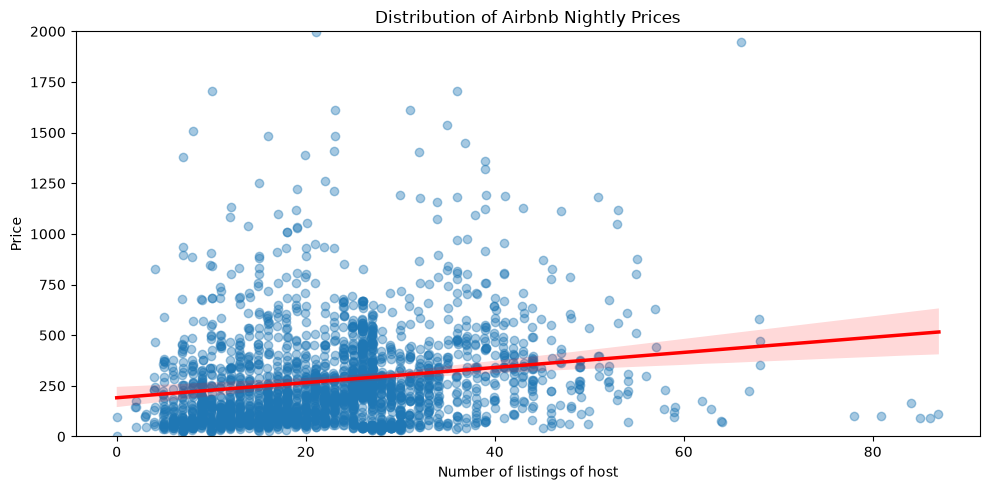

In [ ]:
df_eda['amenities_count'] = df_eda['amenities'].apply(lambda x: len(json.loads(x)))

plt.figure(figsize=(10, 5))
sns.regplot(data=df_eda, x='amenities_count', y='price', x_jitter=0.1, line_kws={'color': 'red', 'linewidth': 2.5}, scatter_kws={'alpha': 0.4, 'color': '#1f77b4'})
plt.ylim(0, 2000)
plt.title("Distribution of Airbnb Nightly Prices")
plt.xlabel("Number of Amenities")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

In [ ]:
amenity_freq = pd.Series(dict(amenity_counts)).sort_values(ascending=False)

top_40_names = amenity_freq.head(40).index

amenity_summary = []

for amenity in top_40_names:
    col = f"has_{amenity}"

    grouped = df_eda.groupby(col)["price"]

    median_prices = grouped.median()
    counts = grouped.size()

    amenity_summary.append({
        "amenity": amenity,
        "count_with": counts.get(1, 0),
        "count_without": counts.get(0, 0),
        "median_with": median_prices.get(1, float("nan")),
        "median_without": median_prices.get(0, float("nan")),
        "median_difference": (
            median_prices.get(1, float("nan"))
            - median_prices.get(0, float("nan"))
        )
    })

amenity_summary = pd.DataFrame(amenity_summary)

amenity_summary.sort_values(
    "median_difference",
    ascending=False
)